This is a VERY simple "CNN" that does not require training (the weights and biases are predetermined).

In [79]:
# !pip install --upgrade keras
# !pip install --upgrade tensorflow

In [80]:
# TensorFlow and tf.keras
import tensorflow as tf
from tensorflow import keras

print(tf.__version__)

# Helper libraries
import numpy as np
import matplotlib.pyplot as plt
import scipy
import array

# fix random seed for reproducibility
seed = 2023
np.random.seed(seed)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Activation
from tensorflow.keras.layers import Conv2D, GlobalMaxPooling2D, ZeroPadding2D
from tensorflow.keras.models import load_model
from tensorflow.keras import Input

2.15.0


In [81]:
# uncomment if you want to use Drive

from google.colab import drive
drive.mount('/content/gdrive')

images_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Images'
models_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Models'
files_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Files'
# !ls '/content/gdrive/My Drive/'

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [82]:
# Get name for training set
train_name_prefix = "ECAs_1024sims-per-rule_64x64"
train_diagram_name = train_name_prefix + "_train_diagrams.npy"
train_diagram_label= train_name_prefix + "_train_labels.npy"

# Load the data. Training set
x_train_all = np.load(f"{files_dir}/{train_diagram_name}")
r_train_all = np.load(f"{files_dir}/{train_diagram_label}")

# pad the data: cylindrical wrapping
depth=1
x_train_all_padded = np.pad(x_train_all, ((0,0),(0,0),(depth,depth),(0,0)), mode='wrap')

Text(0.5, 1.0, 'ECA rule: 116')

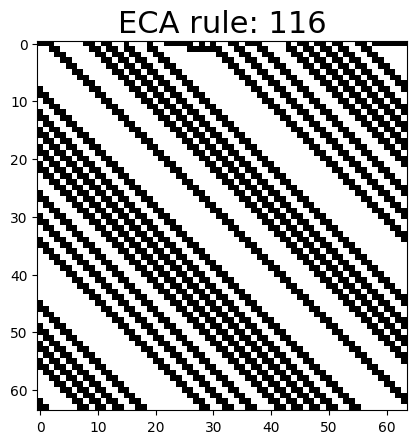

In [83]:
randidx = np.random.randint(x_train_all.shape[0])

x_train_example = x_train_all[randidx,:,:,0]
x_train_example_padded = np.pad(x_train_example, ((0,0),(depth,depth)), mode='wrap')
r_train_example = r_train_all[randidx,0]

plt.imshow(x_train_example, cmap='Greys')
plt.title(f"ECA rule: {r_train_example}", fontsize=22)

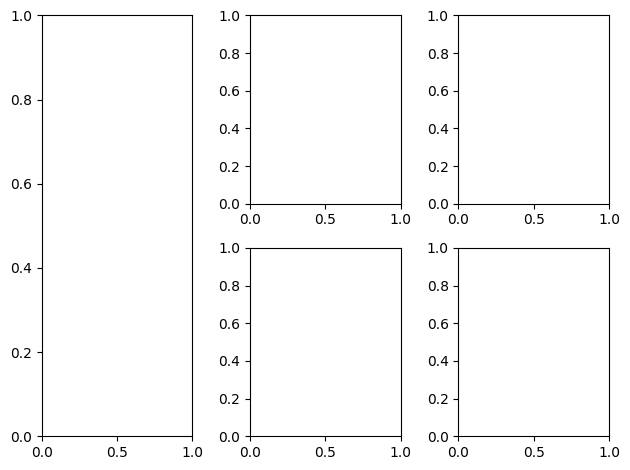

In [114]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(ncols=3, nrows=2)
gs = axs[0, 0].get_gridspec() # second row, third column

# remove the underlying axes, second and third row, final column
for ax in axs[:, 0]:
    ax.remove()
axbig = fig.add_subplot(gs[:, 0])
# axbig.annotate('Big Axes \nGridSpec[1:, -1]', (0.1, 0.5),
#                xycoords='axes fraction', va='center')

fig.tight_layout()

plt.show()

In [110]:
gs[1:, -1]

GridSpec(3, 3)[1:3, 2:3]

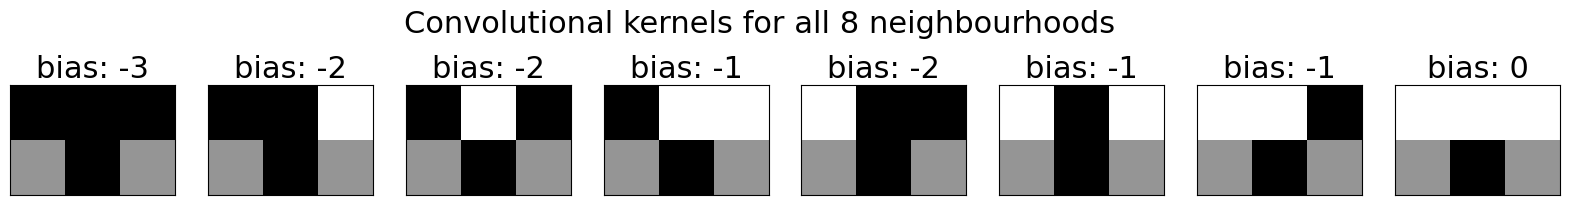

In [84]:
conv_kernels = np.array([[[-1,-1,-1],[0,1,0]],
                         [[-1,-1,+1],[0,1,0]],
                         [[-1,+1,-1],[0,1,0]],
                         [[-1,+1,+1],[0,1,0]],
                         [[+1,-1,-1],[0,1,0]],
                         [[+1,-1,+1],[0,1,0]],
                         [[+1,+1,-1],[0,1,0]],
                         [[+1,+1,+1],[0,1,0]]])
biases = np.array([-np.sum(conv_kernels[i,0,:]==1) for i in range(8)])

fig, axs = plt.subplots(1,8, figsize=(20,2.7))
fontsize = 22

for i in range(8):
    conv_kernel = conv_kernels[-i-1]
    bias = biases[-i-1]
    axs[i].imshow(conv_kernel, cmap='Greys', vmin=-1, vmax=1)
    axs[i].set_xticks([])
    axs[i].set_yticks([])
    axs[i].set_title(f"bias: {bias}", size=fontsize)
_=fig.suptitle("Convolutional kernels for all 8 neighbourhoods", size=fontsize)

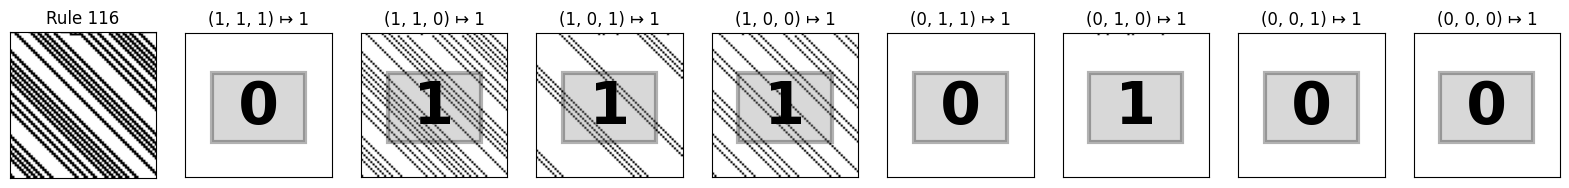

In [85]:
def convolve_diagram(diagram, conv_kernel, bias, activation=None):
  conv = scipy.signal.convolve2d(diagram, np.flip(conv_kernel), mode='valid')
  conv += bias
  if activation == 'relu':
    conv = np.maximum(conv, 0)
  return conv

fig, axs = plt.subplots(1,9, figsize=(20,4))
axs[0].imshow(x_train_example, cmap='Greys')
axs[0].set_xticks([])
axs[0].set_yticks([])
axs[0].set_title(f"Rule {r_train_example}")

tuples = [(0,0,0), (0,0,1), (0,1,0), (0,1,1), (1,0,0), (1,0,1), (1,1,0), (1,1,1)]

for i in range(8):
  conv_kernel = conv_kernels[-i-1]
  bias = biases[-i-1]
  conv = convolve_diagram(x_train_example_padded, conv_kernel, bias, activation='relu')
  axs[i+1].imshow(conv, cmap='Greys')
  axs[i+1].set_xticks([])
  axs[i+1].set_yticks([])
  axs[i+1].set_title(f"{tuples[-i-1]} ↦ 1")
  txt=axs[i+1].text(conv.shape[0]/2, conv.shape[1]/2, f" {np.max(conv)} ", ha='center', va='center', size=42, weight='bold')
  txt.set_bbox(dict(facecolor='grey', alpha=0.3, linewidth=3))

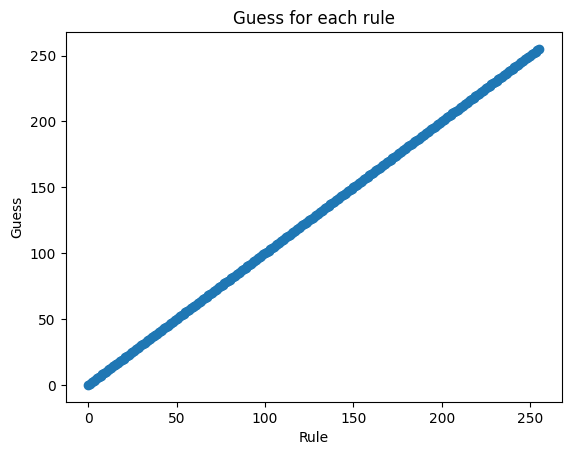

In [86]:
def _base_repr(number, base=2, length=8):
    base_repr = np.base_repr(number, base=base)
    if len(base_repr) < length:
        extra_zeros = (length - len(base_repr)) * '0'
        base_repr = extra_zeros + base_repr
    return base_repr

weight_factor = 10
dense_weights = np.array([[2*int(i)-1 for i in _base_repr(j)] for j in range(256)])
dense_biases = -np.array([_base_repr(j).count('1') for j in range(256)])+1
dense_weights *= weight_factor
dense_biases *= weight_factor

def softmax(x):
    e_x = np.exp(x - np.max(x))
    return e_x / e_x.sum()

rules = np.arange(256)
guesses = []
for rule in rules:
  bin_number = _base_repr(rule)
  bin_array  = np.array(list(array.array('u', bin_number)), dtype='int')

  one_hot_vector = np.zeros(256)
  for i in range(256):
    output = np.dot(dense_weights[i], bin_array) + dense_biases[i]
    one_hot_vector[i] = output

  one_hot_vector = softmax(one_hot_vector)
  guess = np.argmax(one_hot_vector)
  guesses.append(guess)
guesses = np.array(guesses)

plt.plot(rules, guesses, 'o')
plt.xlabel('Rule')
plt.ylabel('Guess')
plt.title('Guess for each rule')
plt.show()

In [87]:
# extremely simple "neural network" for rule identification
# (putting everything in a sequence)

def custom_made_cnn(diagram_dims=(64, 66, 1), output_type='rules'):
    # output_type param should be 'classes', 'independent', or 'rules'
    if output_type == 'rules':
      output_nodes = 256
    elif output_type == 'independent':
      output_nodes = 88
    elif output_type == 'classes':
      output_nodes = 5
    else:
      raise Exception("Parameter 'output_type' should be either 'classes' (5-fold) or 'rules' (256-fold).")

    # tell the model which input shape the samples will have
    inputs = Input(diagram_dims, dtype=tf.float32)

    # Conv block, width = 8
    x = Conv2D(8, (2,3), padding='valid')(inputs)
    x = Activation('relu')(x)

    # Only keep the maximum value of each channel (either 0 or 1)
    x = GlobalMaxPooling2D()(x)

    # The linear classification output layer
    output = Dense(output_nodes, activation="softmax")(x)

    # sequence model
    model = tf.keras.Model(inputs=inputs, outputs=output)

    return model

In [88]:
diagram_dims = (64,66,1)
OUTPUT_TYPE = 'rules'
cnn = custom_made_cnn(diagram_dims=diagram_dims, output_type=OUTPUT_TYPE)
cnn.summary()
cnn.compile()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 64, 66, 1)]       0         
                                                                 
 conv2d_2 (Conv2D)           (None, 63, 64, 8)         56        
                                                                 
 activation_2 (Activation)   (None, 63, 64, 8)         0         
                                                                 
 global_max_pooling2d_2 (Gl  (None, 8)                 0         
 obalMaxPooling2D)                                               
                                                                 
 dense_2 (Dense)             (None, 256)               2304      
                                                                 
Total params: 2360 (9.22 KB)
Trainable params: 2360 (9.22 KB)
Non-trainable params: 0 (0.00 Byte)
___________________________

In [89]:
# get convolutional kernels in correct shape
conv_kernels_cnn = np.expand_dims(np.transpose(conv_kernels, (1,2,0)), axis=2)
conv_kernels_cnn.shape

# get convolutional biases in correct shape
conv_biases_cnn = biases.copy()

# get weights for dense layer in correct shape
dense_weights_cnn = np.flip(dense_weights,axis=1).T

# get biases for dense layer in correct shape
dense_biases_cnn = dense_biases.copy()

# assign weights and biases
cnn.set_weights([conv_kernels_cnn, conv_biases_cnn, dense_weights_cnn, dense_biases_cnn])

In [90]:
# make inferences
CALCULATE_AGAIN=False

if CALCULATE_AGAIN:
  inferences = cnn.predict(x_train_all_padded, verbose=1, batch_size=64)
  inferences = np.argmax(inferences,axis=1)

In [91]:
correct_idx, = np.where(r_train_all[:,0] == inferences)
misidentified_idx, = np.where(r_train_all[:,0] != inferences)

misidentified_idx1, = np.where(r_train_all[:,0] == inferences+1) # 175
# misidentified_idx2, = np.where(r_train_all[:,0] == inferences+2) # 0
misidentified_idx4, = np.where(r_train_all[:,0] == inferences+4) # 9
# misidentified_idx8, = np.where(r_train_all[:,0] == inferences+8) # 0
# misidentified_idx16, = np.where(r_train_all[:,0] == inferences+16) # 0
misidentified_idx32, = np.where(r_train_all[:,0] == inferences+32) # 12
# misidentified_idx64, = np.where(r_train_all[:,0] == inferences+64) # 0
misidentified_idx128, = np.where(r_train_all[:,0] == inferences+128) # 188

r_train_correct = r_train_all[correct_idx,0]
inferences_correct = inferences[correct_idx]

r_train_wrong1 = r_train_all[misidentified_idx1,0]
inferences_wrong1 = inferences[misidentified_idx1]
# r_train_wrong2 = r_train_all[misidentified_idx2,0]
r_train_wrong4 = r_train_all[misidentified_idx4,0]
inferences_wrong4 = inferences[misidentified_idx4]
# r_train_wrong8 = r_train_all[misidentified_idx8,0]
# r_train_wrong16 = r_train_all[misidentified_idx16,0]
r_train_wrong32 = r_train_all[misidentified_idx32,0]
inferences_wrong32 = inferences[misidentified_idx32]
# r_train_wrong64 = r_train_all[misidentified_idx64,0]
r_train_wrong128 = r_train_all[misidentified_idx128,0]
inferences_wrong128 = inferences[misidentified_idx128]

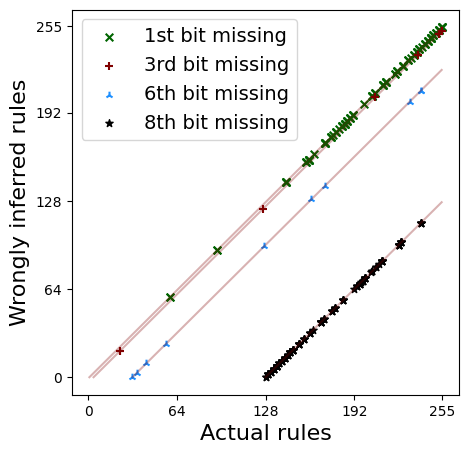

In [92]:
fig, ax = plt.subplots(1,1,figsize=(5,5))
# ax.plot(r_train_correct, inferences_correct, color='darkgreen', ls='--', lw=4)

s=30
cs=['darkgreen', 'maroon', 'dodgerblue', 'black']

ax.scatter(r_train_wrong1, inferences_wrong1, s=s, c=cs[0], marker='x', label="1st bit missing")
ax.plot([1,255],[0, 254], c=c, alpha=.3)

ax.scatter(r_train_wrong4, inferences_wrong4, s=s, c=cs[1], marker='+', label="3rd bit missing")
ax.plot([4, 255],[0, 251], c=c, alpha=.3)

ax.scatter(r_train_wrong32, inferences_wrong32, s=s, c=cs[2], marker='2', label="6th bit missing")
ax.plot([32, 255],[0, 255-32], c=c, alpha=.3)

ax.scatter(r_train_wrong128, inferences_wrong128, s=s, c=cs[3], marker='*', label="8th bit missing")
ax.plot([128, 255],[0, 255-128], c=c, alpha=.3)

ticks = [0, 32, 64, 96, 128, 160, 192, 224, 255]

ax.set_xticks(ticks[::2])
ax.set_yticks(ticks[::2])

ax.set_xlabel("Actual rules", size=16)
ax.set_ylabel("Wrongly inferred rules", size=16)

ax.legend(loc='upper left', fontsize=14)

plt.show()

Text(0.5, 1.0, 'Rule 171, inferred as 170')

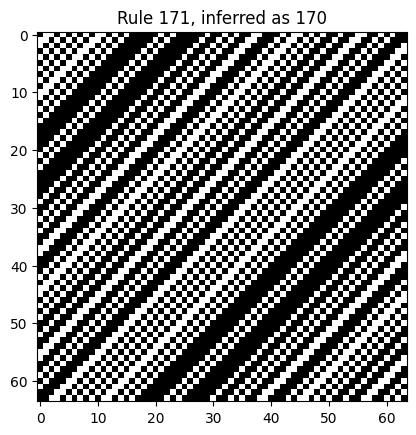

In [93]:
# show misclassified examples

idx1 = np.random.choice(misidentified_idx1)
plt.imshow(x_train_all[idx1], cmap='Greys')
plt.title(f'Rule {r_train_all[idx1,0]}, inferred as {inferences[idx1]}')

# x_train_all.shape[0] - len(correct_idx) # almost as good as scanning and guessing